# 🎯 04 — Model 1: Player Similarity Engine
### Scouti Kora — AI Football Scouting System

**What this model does:**
Given any player, find the N most statistically similar players across all leagues/seasons.

**Design decisions:**
- Uses **cosine similarity** (measures style direction, not volume)
- Uses **per-90 stats** as the feature vector (playing style, not raw output)
- Does **NOT** use market value, wages, age in the similarity vector (we want style-based similarity)
- Supports **position filtering**: find similar within same position OR across all positions
- Supports **multi-season**: use latest season, specific season, or career average
- Multi-hot positions: a `MF,FW` player can match both midfielders and forwards

---
**Input:** `data/processed/master_scouting_dataset.csv`  
**Output:** `data/processed/similarity_model.pkl` + `data/processed/player_index.csv`

## 📦 0 — Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import pickle
import warnings
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import PCA

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', '{:.3f}'.format)
pd.set_option('display.max_rows', 30)

ROOT      = Path('..').resolve()
PROCESSED = ROOT / 'data' / 'processed'
REPORTS   = ROOT / 'reports'

COLORS = ['#7F77DD','#1D9E75','#D85A30','#378ADD','#BA7517','#D4537E']
POS_COLORS = {'Forward':COLORS[2], 'Midfielder':COLORS[0],
               'Defender':COLORS[1], 'Goalkeeper':COLORS[3]}

plt.rcParams.update({
    'figure.facecolor':'white','axes.facecolor':'white',
    'axes.grid':True,'grid.alpha':0.3,
    'axes.spines.top':False,'axes.spines.right':False,
})

print('✅ Ready')

✅ Ready


## 📂 1 — Load Master Dataset

In [2]:
df = pd.read_csv(PROCESSED / 'master_scouting_dataset.csv', low_memory=False)
print(f'Master dataset: {len(df):,} rows × {len(df.columns)} cols')
print(f'Unique players: {df["Player"].nunique():,}')
print(f'Seasons: {sorted(df["season"].unique())}')
print(f'Leagues: {sorted(df["league"].unique())}')
print()

# Confirm position multi-hot columns
print('Multi-hot position check:')
for p in ['pos_FW','pos_MF','pos_DF','pos_GK','is_versatile']:
    print(f'  {p}: {int(df[p].sum()):,} players flagged')

Master dataset: 11,888 rows × 69 cols
Unique players: 4,817
Seasons: ['2020-2021', '2021-2022', '2022-2023', '2023-2024', '2024-2025']
Leagues: ['Bundesliga', 'EPL', 'LaLiga', 'Ligue1', 'SerieA']

Multi-hot position check:
  pos_FW: 3,012 players flagged
  pos_MF: 6,407 players flagged
  pos_DF: 4,342 players flagged
  pos_GK: 968 players flagged
  is_versatile: 2,841 players flagged


## 🎯 2 — Define Similarity Feature Vector
**Rule:** Only per-90 stats + position flags. NOT raw counts, NOT market value, NOT age.
Cosine similarity on per-90 captures HOW a player plays, not HOW MUCH.

In [3]:
# ── Core per-90 similarity features ────────────────────
# These define playing STYLE. Two players with similar per-90 vectors
# play football the same way regardless of club or league level.

SIMILARITY_FEATURES = [
    # Attacking output
    'goals_p90',          # goal scorer signal
    'assists_p90',        # creator signal
    'g_a_p90',            # combined attacking contribution
    'shots_p90',          # shot volume (aggression)

    # Shooting quality (rate-based — no per-90 needed)
    'shot_accuracy_pct',  # precision
    'conversion_rate',    # finishing efficiency

    # Defensive contribution
    'tackles_won_p90',    # defensive engagement
    'interceptions_p90',  # reading the game
    'def_actions_p90',    # total defensive work rate

    # Discipline
    'yellow_p90',         # aggression / fouling tendency

    # Availability
    'availability_pct',   # how often fit to play

    # Position (multi-hot — captures positional versatility)
    'pos_FW',
    'pos_MF',
    'pos_DF',
    'pos_GK',
]

# Only keep features that exist and have sufficient data
available_features = [
    f for f in SIMILARITY_FEATURES
    if f in df.columns and df[f].notna().mean() > 0.5
]

missing = [f for f in SIMILARITY_FEATURES if f not in available_features]
print(f'Similarity features: {len(available_features)}')
print(f'Available: {available_features}')
if missing:
    print(f'Missing:   {missing}')

print()
print('WHY these features and NOT others:')
print('  ✅ goals_p90     — style: goal scorer vs non-scorer')
print('  ✅ assists_p90   — style: creator vs finisher')
print('  ✅ tackles_p90   — style: aggressive presser vs passive')
print('  ✅ pos_FW/MF/DF  — position context for similarity')
print('  ❌ market_value  — NOT style, just fame/price')
print('  ❌ age           — NOT style, young Lewandowski ≈ old Lewandowski')
print('  ❌ goals (raw)   — NOT style, a player with 300 mins vs 3000 mins')

Similarity features: 15
Available: ['goals_p90', 'assists_p90', 'g_a_p90', 'shots_p90', 'shot_accuracy_pct', 'conversion_rate', 'tackles_won_p90', 'interceptions_p90', 'def_actions_p90', 'yellow_p90', 'availability_pct', 'pos_FW', 'pos_MF', 'pos_DF', 'pos_GK']

WHY these features and NOT others:
  ✅ goals_p90     — style: goal scorer vs non-scorer
  ✅ assists_p90   — style: creator vs finisher
  ✅ tackles_p90   — style: aggressive presser vs passive
  ✅ pos_FW/MF/DF  — position context for similarity
  ❌ market_value  — NOT style, just fame/price
  ❌ age           — NOT style, young Lewandowski ≈ old Lewandowski
  ❌ goals (raw)   — NOT style, a player with 300 mins vs 3000 mins


## 🗂️ 3 — Build Player Index
Decide which row to use per player: **latest season** = current form.
Also keep multi-season option for historical analysis.

In [4]:
# ── Strategy: use latest season per player ──────────────
# Reason: we want current playing style, not 5-year average
# A striker who became a winger 2 seasons ago should reflect the winger style

SEASON_ORDER = {
    '2020-2021': 1, '2021-2022': 2,
    '2022-2023': 3, '2023-2024': 4, '2024-2025': 5
}
df['season_rank'] = df['season'].map(SEASON_ORDER).fillna(0)

# Latest season per player
player_index = (
    df.sort_values('season_rank', ascending=False)
    .drop_duplicates('Player', keep='first')
    .reset_index(drop=True)
)

# Also keep ALL seasons version (for multi-season similarity)
player_all_seasons = df.copy()

print(f'Player index (latest season): {len(player_index):,} unique players')
print(f'Season distribution:')
print(player_index['season'].value_counts().sort_index().to_string())
print(f'\nPosition breakdown:')
print(player_index['primary_pos'].value_counts().to_string())
print(f'\nLeague breakdown:')
print(player_index['league'].value_counts().to_string())

Player index (latest season): 4,817 unique players
Season distribution:
season
2020-2021     546
2021-2022     582
2022-2023     601
2023-2024     696
2024-2025    2392

Position breakdown:
primary_pos
Midfielder    2102
Defender      1501
Forward        806
Goalkeeper     408

League breakdown:
league
Ligue1        1068
LaLiga        1027
SerieA        1020
EPL            867
Bundesliga     835


## 🔧 4 — Prepare Feature Matrix & Scale

In [5]:
# ── Build feature matrix ────────────────────────────────
X_raw = player_index[available_features].copy()

# Fill missing values
# Strategy: per feature type
for col in available_features:
    if col in ['pos_FW','pos_MF','pos_DF','pos_GK']:
        X_raw[col] = X_raw[col].fillna(0)   # binary — 0 if unknown
    elif col == 'availability_pct':
        X_raw[col] = X_raw[col].fillna(X_raw[col].median())
    elif 'pct' in col or 'rate' in col or 'quality' in col:
        X_raw[col] = X_raw[col].fillna(0)   # rate: 0 = no shots
    else:
        X_raw[col] = X_raw[col].fillna(0)   # per-90: 0 = no contribution

# Clip extreme outliers (99th percentile) before scaling
# Prevents one Lewandowski from warping the entire space
for col in available_features:
    if col not in ['pos_FW','pos_MF','pos_DF','pos_GK']:
        cap = X_raw[col].quantile(0.99)
        X_raw[col] = X_raw[col].clip(upper=cap)

# Scale: StandardScaler ensures all features contribute equally
# (otherwise goals_p90 range 0-1.5 would dominate availability_pct range 0-100)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)
X_scaled = pd.DataFrame(X_scaled, columns=available_features, index=player_index.index)

print(f'Feature matrix: {X_scaled.shape[0]:,} players × {X_scaled.shape[1]} features')
print(f'Null count after prep: {X_scaled.isnull().sum().sum()}')
print()
print('Feature stats after scaling (should be mean≈0, std≈1):')
stats = X_scaled.describe().loc[['mean','std']].round(3)
print(stats.to_string())

Feature matrix: 4,817 players × 15 features
Null count after prep: 0

Feature stats after scaling (should be mean≈0, std≈1):
      goals_p90  assists_p90  g_a_p90  shots_p90  shot_accuracy_pct  conversion_rate  tackles_won_p90  interceptions_p90  def_actions_p90  yellow_p90  availability_pct  pos_FW  pos_MF  pos_DF  pos_GK
mean      0.000       -0.000    0.000     -0.000              0.000           -0.000            0.000              0.000            0.000       0.000            -0.000  -0.000  -0.000  -0.000  -0.000
std       1.000        1.000    1.000      1.000              1.000            1.000            1.000              1.000            1.000       1.000             1.000   1.000   1.000   1.000   1.000


## 🤖 5 — Build KNN Model (Cosine Similarity)

In [6]:
# ── Build KNN model ──────────────────────────────────────
# metric='cosine' → finds players whose feature DIRECTION is similar
# This is better than euclidean for football stats because:
#   A player scoring 0.5 goals/90 in a weak league vs a strong league
#   should be considered similar if all other ratios match

N_NEIGHBORS = 20   # find top 20 — user can request top 5, 10, etc.

knn_model = NearestNeighbors(
    n_neighbors=N_NEIGHBORS + 1,  # +1 because the player itself is always #1
    metric='cosine',
    algorithm='brute',            # brute force — dataset is small enough
    n_jobs=-1
)
knn_model.fit(X_scaled)

# Also compute full cosine similarity matrix for reference
cosine_matrix = cosine_similarity(X_scaled)
cosine_df = pd.DataFrame(
    cosine_matrix,
    index=player_index['Player'].values,
    columns=player_index['Player'].values
)

print(f'✅ KNN model trained: {X_scaled.shape[0]:,} players × {X_scaled.shape[1]} features')
print(f'   Metric: cosine similarity')
print(f'   Returns top: {N_NEIGHBORS} neighbors per query')
print(f'   Algorithm: brute force (exact, not approximate)')

✅ KNN model trained: 4,817 players × 15 features
   Metric: cosine similarity
   Returns top: 20 neighbors per query
   Algorithm: brute force (exact, not approximate)


## 🔍 6 — Similarity Functions
Two functions:
1. `find_similar()` — core function, used by the recommendation engine
2. `compare_players()` — side-by-side stat comparison for the UI

In [7]:
def find_similar(
    player_name: str,
    top_n: int = 10,
    same_position: bool = False,
    position_filter: str = None,      # 'Forward','Midfielder','Defender','Goalkeeper'
    exclude_same_club: bool = False,
    min_minutes: int = 450,           # at least 5 full games
    season: str = None,               # None = latest season
) -> pd.DataFrame:
    """
    Find the most similar players to a given player.

    Args:
        player_name:       Exact name (case-sensitive) or partial match
        top_n:             Number of similar players to return
        same_position:     If True, only return players with same primary_pos
        position_filter:   Override: filter to specific position regardless of reference player
        exclude_same_club: If True, exclude teammates
        min_minutes:       Minimum minutes played for candidates
        season:            Specific season or None for latest

    Returns:
        DataFrame with similar players + similarity scores + key stats
    """
    # ── Find the reference player ──────────────────────
    # Exact match first
    ref_mask = player_index['Player'] == player_name

    # Partial match fallback
    if not ref_mask.any():
        ref_mask = player_index['Player'].str.contains(
            player_name, case=False, na=False
        )

    if not ref_mask.any():
        print(f'❌ Player "{player_name}" not found.')
        # Show suggestions
        suggestions = player_index[
            player_index['Player'].str.lower().str.contains(
                player_name.lower().split()[0], na=False
            )
        ]['Player'].head(5).tolist()
        if suggestions:
            print(f'   Did you mean: {suggestions}')
        return pd.DataFrame()

    ref_row  = player_index[ref_mask].iloc[0]
    ref_idx  = ref_mask.idxmax()
    ref_vec  = X_scaled.loc[ref_idx].values.reshape(1, -1)

    print(f'🔍 Reference: {ref_row["Player"]} '
          f'({ref_row["Squad"]}, {ref_row["league"]}, {ref_row["season"]}) '
          f'[{ref_row["primary_pos"]}]')

    # ── Build candidate pool ───────────────────────────
    candidates = player_index.copy()

    # Filter by minimum minutes
    candidates = candidates[candidates['minutes_played'] >= min_minutes]

    # Position filter using multi-hot columns
    if same_position:
        pos = ref_row['primary_pos']
        pos_col_map = {
            'Forward':'pos_FW','Midfielder':'pos_MF',
            'Defender':'pos_DF','Goalkeeper':'pos_GK'
        }
        col = pos_col_map.get(pos)
        if col and col in candidates.columns:
            candidates = candidates[candidates[col] == 1]
            print(f'   Position filter: {pos} ({len(candidates):,} candidates)')

    elif position_filter:
        pos_col_map = {
            'Forward':'pos_FW','Midfielder':'pos_MF',
            'Defender':'pos_DF','Goalkeeper':'pos_GK'
        }
        col = pos_col_map.get(position_filter)
        if col and col in candidates.columns:
            candidates = candidates[candidates[col] == 1]
            print(f'   Position filter: {position_filter} ({len(candidates):,} candidates)')

    if exclude_same_club:
        candidates = candidates[candidates['Squad'] != ref_row['Squad']]

    # Remove the reference player from candidates
    candidates = candidates[candidates['Player'] != ref_row['Player']]

    # ── Compute cosine similarity against candidates ───
    cand_idx  = candidates.index
    X_cands   = X_scaled.loc[cand_idx]

    sims = cosine_similarity(ref_vec, X_cands)[0]

    # Build result DataFrame
    result = candidates.copy()
    result['similarity_score'] = sims
    result['similarity_pct']   = (sims * 100).round(1)

    result = result.sort_values('similarity_score', ascending=False).head(top_n)

    # Select display columns
    display_cols = [
        'Player','primary_pos','Squad','league','season',
        'goals_p90','assists_p90','tackles_won_p90',
        'attack_score','defense_score','market_value_eur',
        'similarity_score','similarity_pct'
    ]
    display_cols = [c for c in display_cols if c in result.columns]

    print(f'   Found {len(result)} similar players')
    return result[display_cols]


def compare_players(player_a: str, player_b: str) -> pd.DataFrame:
    """
    Side-by-side stat comparison between two players.
    Returns a DataFrame with both players' stats for easy comparison.
    """
    COMPARE_COLS = [
        'Player','primary_pos','Squad','league','season','Age',
        'games_played','minutes_played','availability_pct',
        'goals','assists','goals_p90','assists_p90','g_a_p90',
        'shots_p90','shot_accuracy_pct','conversion_rate',
        'tackles_won_p90','interceptions_p90','def_actions_p90',
        'yellow_p90','attack_score','defense_score','overall_score',
        'market_value_eur','weekly_eur','value_efficiency'
    ]

    rows = []
    for name in [player_a, player_b]:
        mask = player_index['Player'].str.contains(name, case=False, na=False)
        if mask.any():
            rows.append(player_index[mask].iloc[0])
        else:
            print(f'⚠️  {name} not found')

    if not rows:
        return pd.DataFrame()

    compare = pd.DataFrame(rows)
    available = [c for c in COMPARE_COLS if c in compare.columns]
    return compare[available].set_index('Player').T


print('✅ find_similar() and compare_players() defined')

✅ find_similar() and compare_players() defined


## 🧪 7 — Test: Find Similar Players to Known Stars

In [8]:
# ── Test 1: Pure striker — Lewandowski ───────────────────
print('='*60)
print('TEST 1: Players similar to Robert Lewandowski (striker)')
print('='*60)
sim1 = find_similar('Lewandowski', top_n=10, same_position=True)
print(sim1.to_string(index=False))

TEST 1: Players similar to Robert Lewandowski (striker)
🔍 Reference: Robert Lewandowski (Barcelona, LaLiga, 2024-2025) [Forward]
   Position filter: Forward (870 candidates)
   Found 10 similar players
           Player primary_pos            Squad     league    season  goals_p90  assists_p90  tackles_won_p90  attack_score  defense_score  market_value_eur  similarity_score  similarity_pct
Jonathan Burkardt     Forward         Mainz 05 Bundesliga 2024-2025      0.768        0.085            0.299         5.320          0.370      35000000.000             0.991          99.100
    Kylian Mbappé     Forward      Real Madrid     LaLiga 2024-2025      0.960        0.093            0.155         6.240          0.200     200000000.000             0.991          99.100
   Erling Haaland     Forward  Manchester City        EPL 2024-2025      0.724        0.099            0.197         5.190          0.410     200000000.000             0.990          99.000
  Serhou Guirassy     Forward         

In [9]:
# ── Test 2: Elite midfielder — across all positions ───────
print('='*60)
print('TEST 2: Players similar to Kylian Mbappé (all positions)')
print('='*60)
sim2 = find_similar('Mbappé', top_n=10, same_position=False)
print(sim2.to_string(index=False))

TEST 2: Players similar to Kylian Mbappé (all positions)
🔍 Reference: Kylian Mbappé (Real Madrid, LaLiga, 2024-2025) [Forward]
   Found 10 similar players
            Player primary_pos            Squad     league    season  goals_p90  assists_p90  tackles_won_p90  attack_score  defense_score  market_value_eur  similarity_score  similarity_pct
    Erling Haaland     Forward  Manchester City        EPL 2024-2025      0.724        0.099            0.197         5.190          0.410     200000000.000             0.994          99.400
Robert Lewandowski     Forward        Barcelona     LaLiga 2024-2025      0.911        0.067            0.169         5.980          0.350       8000000.000             0.991          99.100
        Moise Kean     Forward       Fiorentina     SerieA 2024-2025      0.632        0.100            0.166         4.800          0.430      40000000.000             0.989          98.900
 Alexander Sørloth     Forward  Atlético Madrid     LaLiga 2024-2025      1.149  

In [10]:
# ── Test 3: Defensive midfielder ──────────────────────────
print('='*60)
print('TEST 3: Players similar to Mohamed Salah')
print('='*60)
sim3 = find_similar('Salah', top_n=10)
print(sim3.to_string(index=False))

TEST 3: Players similar to Mohamed Salah
🔍 Reference: Mohamed Salah (Liverpool, EPL, 2024-2025) [Midfielder]
   Found 10 similar players
            Player primary_pos         Squad     league    season  goals_p90  assists_p90  tackles_won_p90  attack_score  defense_score  market_value_eur  similarity_score  similarity_pct
        Leroy Sané  Midfielder Bayern Munich Bundesliga 2024-2025      0.605        0.275            0.770         5.450          1.290      22000000.000             0.966          96.600
     Michael Olise  Midfielder Bayern Munich Bundesliga 2024-2025      0.463        0.578            0.771         5.950          1.200     140000000.000             0.962          96.200
     Dimitri Payet  Midfielder     Marseille     Ligue1 2022-2023      0.431        0.323            0.539         4.540          0.560       1800000.000             0.953          95.300
     Florian Wirtz  Midfielder    Leverkusen Bundesliga 2024-2025      0.383        0.459            0.842     

In [11]:
# ── Test 4: Use case — find cheap Mbappe alternatives ─────
print('='*60)
print('TEST 4: Cheap similar to Mbappé (value_efficiency focus)')
print('        Use case: club can\'t afford Mbappé, find similar cheaper player')
print('='*60)
sim4 = find_similar('Mbappé', top_n=15, same_position=True)
if not sim4.empty and 'market_value_eur' in sim4.columns:
    # Filter to cheaper alternatives
    ref_value = player_index[player_index['Player'].str.contains('Mbappé',na=False)]['market_value_eur'].iloc[0]
    print(f'Reference market value: €{ref_value/1e6:.0f}M')
    budget_alternatives = sim4[
        pd.to_numeric(sim4['market_value_eur'], errors='coerce') <
        (ref_value * 0.5 if ref_value > 0 else 50_000_000)
    ]
    print(f'\nAlternatives under 50% of reference value:')
    print(budget_alternatives.to_string(index=False))

TEST 4: Cheap similar to Mbappé (value_efficiency focus)
        Use case: club can't afford Mbappé, find similar cheaper player
🔍 Reference: Kylian Mbappé (Real Madrid, LaLiga, 2024-2025) [Forward]
   Position filter: Forward (870 candidates)
   Found 15 similar players
Reference market value: €200M

Alternatives under 50% of reference value:
            Player primary_pos           Squad     league    season  goals_p90  assists_p90  tackles_won_p90  attack_score  defense_score  market_value_eur  similarity_score  similarity_pct
Robert Lewandowski     Forward       Barcelona     LaLiga 2024-2025      0.911        0.067            0.169         5.980          0.350       8000000.000             0.991          99.100
        Moise Kean     Forward      Fiorentina     SerieA 2024-2025      0.632        0.100            0.166         4.800          0.430      40000000.000             0.989          98.900
 Alexander Sørloth     Forward Atlético Madrid     LaLiga 2024-2025      1.149      

In [12]:
# ── Test 5: Multi-position player ─────────────────────────
print('='*60)
print('TEST 5: Versatile player (MF,FW) — find similar midfielders')
print('        Multi-hot encoding means versatile players appear in position filter')
print('='*60)

# Find a versatile player
versatile = player_index[player_index['is_versatile']==1].nlargest(1,'attack_score')
if not versatile.empty:
    vname = versatile.iloc[0]['Player']
    print(f'Versatile player: {vname} (Pos: {versatile.iloc[0]["Pos"] if "Pos" in versatile.columns else "N/A"})')
    sim5 = find_similar(vname, top_n=10, position_filter='Midfielder')
    print(f'\nSimilar midfielders (including versatile MF,FW players):')
    print(sim5.to_string(index=False))

TEST 5: Versatile player (MF,FW) — find similar midfielders
        Multi-hot encoding means versatile players appear in position filter
Versatile player: Ferrán Torres (Pos: N/A)
🔍 Reference: Ferrán Torres (Barcelona, LaLiga, 2024-2025) [Forward]
   Position filter: Midfielder (1,899 candidates)
   Found 10 similar players

Similar midfielders (including versatile MF,FW players):
            Player primary_pos               Squad     league    season  goals_p90  assists_p90  tackles_won_p90  attack_score  defense_score  market_value_eur  similarity_score  similarity_pct
Georges Mikautadze     Forward                Lyon     Ligue1 2024-2025      0.683        0.373            0.373         6.010          0.700      28000000.000             0.983          98.300
      Serge Gnabry  Midfielder       Bayern Munich Bundesliga 2024-2025      0.507        0.362            0.725         5.300          1.310      20000000.000             0.976          97.600
     Karim Adeyemi  Midfielder    

## 📊 8 — Visualization: Similarity Radar Chart

🔍 Reference: Robert Lewandowski (Barcelona, LaLiga, 2024-2025) [Forward]
   Position filter: Forward (870 candidates)
   Found 3 similar players


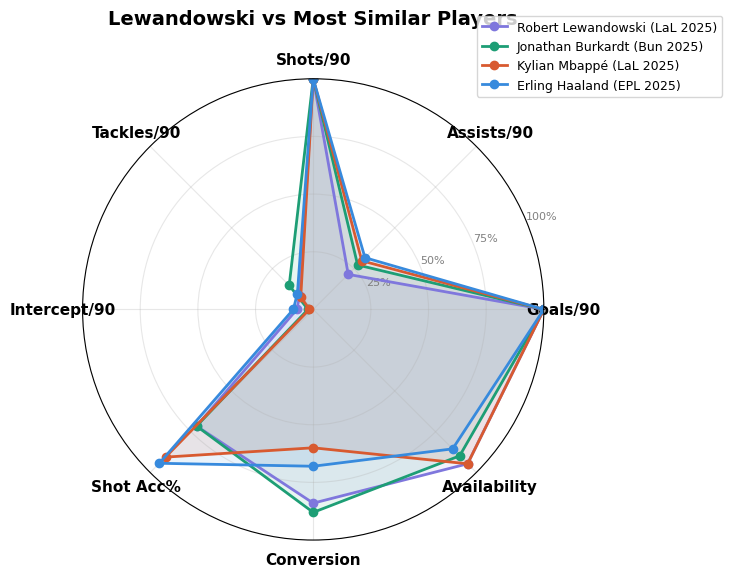

💾 Saved → reports/06_radar_similarity.png


In [13]:
def plot_radar(players_list, title='Player Comparison', save_path=None):
    """
    Radar chart comparing up to 5 players across key metrics.
    Uses normalized (0-1) values so all metrics are comparable.
    """
    RADAR_COLS = [
        'goals_p90','assists_p90','shots_p90',
        'tackles_won_p90','interceptions_p90',
        'shot_accuracy_pct','conversion_rate',
        'availability_pct'
    ]
    RADAR_LABELS = [
        'Goals/90','Assists/90','Shots/90',
        'Tackles/90','Intercept/90',
        'Shot Acc%','Conversion','Availability'
    ]

    available = [c for c in RADAR_COLS if c in player_index.columns]
    labels    = [RADAR_LABELS[RADAR_COLS.index(c)] for c in available]
    n_cats    = len(available)

    if n_cats < 3:
        print('Not enough features for radar chart')
        return

    angles = np.linspace(0, 2*np.pi, n_cats, endpoint=False).tolist()
    angles += angles[:1]   # close the polygon

    fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

    # Compute global min/max for normalization
    norm_vals = {}
    for col in available:
        col_data = pd.to_numeric(player_index[col], errors='coerce').fillna(0)
        mn, mx = col_data.quantile(0.05), col_data.quantile(0.95)
        norm_vals[col] = (mn, mx)

    for i, player_name in enumerate(players_list[:5]):
        mask = player_index['Player'].str.contains(player_name, case=False, na=False)
        if not mask.any():
            print(f'  ⚠️  {player_name} not found')
            continue

        row   = player_index[mask].iloc[0]
        color = COLORS[i % len(COLORS)]

        values = []
        for col in available:
            v   = float(pd.to_numeric(row.get(col, 0), errors='coerce') or 0)
            mn, mx = norm_vals[col]
            normalized = (v - mn) / (mx - mn) if mx > mn else 0
            values.append(np.clip(normalized, 0, 1))

        values += values[:1]   # close polygon

        label = f"{row['Player']} ({row['league'][:3]} {row['season'][-4:]})"
        ax.plot(angles, values, 'o-', linewidth=2, color=color, label=label)
        ax.fill(angles, values, alpha=0.1, color=color)

    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(labels, fontsize=11, fontweight='bold')
    ax.set_ylim(0, 1)
    ax.set_yticks([0.25, 0.5, 0.75, 1.0])
    ax.set_yticklabels(['25%','50%','75%','100%'], fontsize=8, color='gray')
    ax.set_title(title, fontsize=14, fontweight='bold', pad=20)
    ax.legend(loc='upper right', bbox_to_anchor=(1.4, 1.15), fontsize=9)
    ax.grid(True, alpha=0.3)

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()


# Plot 1: Lewandowski vs his top 3 similar players
sim_lewa = find_similar('Lewandowski', top_n=3, same_position=True)
if not sim_lewa.empty:
    similar_names = sim_lewa['Player'].tolist()
    plot_radar(
        ['Lewandowski'] + similar_names[:3],
        title='Lewandowski vs Most Similar Players',
        save_path=REPORTS/'06_radar_similarity.png'
    )
print('💾 Saved → reports/06_radar_similarity.png')

## 🗺️ 9 — Visualization: PCA Player Space

PCA variance explained: PC1=28.7%  PC2=20.6%  Total=49.3%


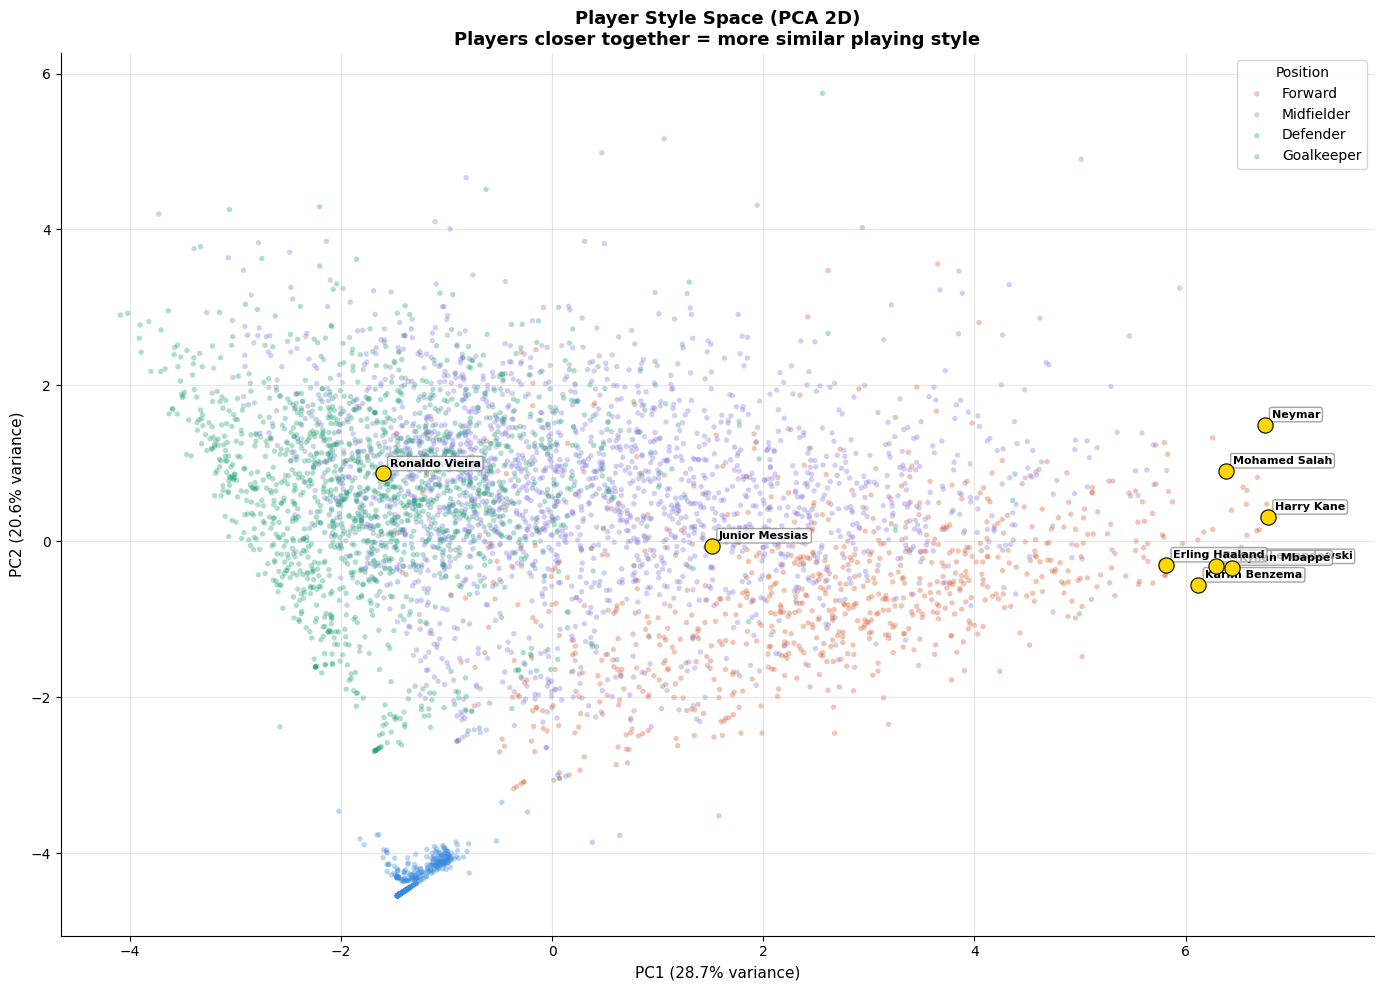

💾 Saved → reports/07_pca_player_space.png


In [14]:
# ── PCA to 2D for visualization ──────────────────────────
# Compress 15 features → 2 dimensions for plotting
# Players near each other in this space = similar playing style

pca = PCA(n_components=2, random_state=42)
X_2d = pca.fit_transform(X_scaled)

var_explained = pca.explained_variance_ratio_ * 100
print(f'PCA variance explained: PC1={var_explained[0]:.1f}%  PC2={var_explained[1]:.1f}%  Total={sum(var_explained):.1f}%')

pca_df = pd.DataFrame(X_2d, columns=['PC1','PC2'], index=player_index.index)
pca_df['Player']      = player_index['Player'].values
pca_df['primary_pos'] = player_index['primary_pos'].values
pca_df['league']      = player_index['league'].values
pca_df['goals_p90']   = player_index['goals_p90'].values

fig, ax = plt.subplots(figsize=(14, 10))

for pos, color in POS_COLORS.items():
    mask = pca_df['primary_pos'] == pos
    ax.scatter(
        pca_df[mask]['PC1'], pca_df[mask]['PC2'],
        c=color, alpha=0.35, s=15, label=pos, edgecolors='none'
    )

# Highlight well-known players
HIGHLIGHT = [
    'Lewandowski','Mbappé','Salah','Ronaldo','Messi',
    'Haaland','Kane','Benzema','Neymar'
]
for name in HIGHLIGHT:
    mask = pca_df['Player'].str.contains(name, case=False, na=False)
    if mask.any():
        row = pca_df[mask].iloc[0]
        ax.scatter(row['PC1'], row['PC2'], c='gold', s=120,
                   zorder=5, edgecolors='black', linewidth=0.8)
        ax.annotate(row['Player'], (row['PC1'], row['PC2']),
                    xytext=(5, 5), textcoords='offset points',
                    fontsize=8, fontweight='bold',
                    bbox=dict(boxstyle='round,pad=0.2', facecolor='white',
                              edgecolor='gray', alpha=0.7))

ax.set_xlabel(f'PC1 ({var_explained[0]:.1f}% variance)', fontsize=11)
ax.set_ylabel(f'PC2 ({var_explained[1]:.1f}% variance)', fontsize=11)
ax.set_title('Player Style Space (PCA 2D)\nPlayers closer together = more similar playing style',
             fontsize=13, fontweight='bold')
ax.legend(title='Position', fontsize=10, title_fontsize=10)

plt.tight_layout()
plt.savefig(REPORTS/'07_pca_player_space.png', dpi=150, bbox_inches='tight')
plt.show()
print('💾 Saved → reports/07_pca_player_space.png')

## 📊 10 — Visualization: Similarity Heatmap (Top Strikers)

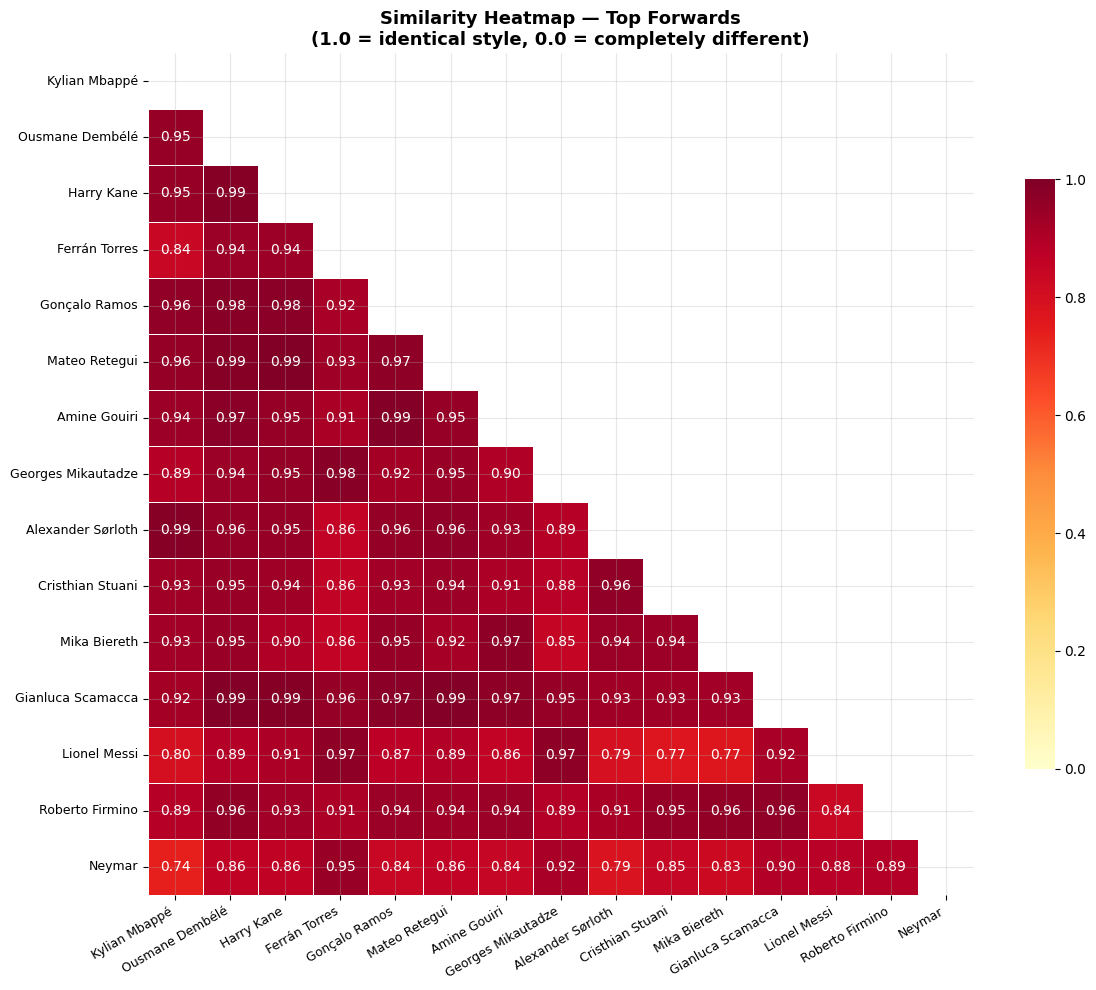

💾 Saved → reports/08_similarity_heatmap_fwd.png


In [15]:
# Pick top 15 forwards by attack_score for heatmap
top_fwd = (
    player_index[
        (player_index['pos_FW'] == 1) &
        (player_index['minutes_played'] >= 900)
    ]
    .nlargest(15, 'attack_score')['Player'].tolist()
)

if len(top_fwd) >= 5:
    # Get similarity scores between these players
    fwd_mask = player_index['Player'].isin(top_fwd)
    fwd_idx  = player_index[fwd_mask].index
    X_fwd    = X_scaled.loc[fwd_idx]
    sim_matrix = cosine_similarity(X_fwd)
    sim_names  = player_index.loc[fwd_idx, 'Player'].values

    fig, ax = plt.subplots(figsize=(12, 10))
    mask = np.triu(np.ones_like(sim_matrix, dtype=bool))
    sns.heatmap(
        sim_matrix,
        mask=mask,
        annot=True, fmt='.2f', cmap='YlOrRd',
        xticklabels=sim_names, yticklabels=sim_names,
        vmin=0, vmax=1, ax=ax,
        linewidths=0.5, cbar_kws={'shrink':0.7}
    )
    ax.set_title('Similarity Heatmap — Top Forwards\n(1.0 = identical style, 0.0 = completely different)',
                 fontsize=13, fontweight='bold')
    plt.xticks(rotation=30, ha='right', fontsize=9)
    plt.yticks(fontsize=9)
    plt.tight_layout()
    plt.savefig(REPORTS/'08_similarity_heatmap_fwd.png', dpi=150, bbox_inches='tight')
    plt.show()
    print('💾 Saved → reports/08_similarity_heatmap_fwd.png')
else:
    print('Not enough forwards found for heatmap')

## 📊 11 — Visualization: Side-by-Side Stat Comparison

In [16]:
# Compare two players side-by-side
comparison = compare_players('Lewandowski', 'Haaland')

if not comparison.empty:
    print('LEWANDOWSKI vs HAALAND:')
    print(comparison.to_string())

    # Compute similarity score between them
    mask_a = player_index['Player'].str.contains('Lewandowski', case=False, na=False)
    mask_b = player_index['Player'].str.contains('Haaland',     case=False, na=False)
    if mask_a.any() and mask_b.any():
        va = X_scaled.loc[mask_a.idxmax()].values.reshape(1,-1)
        vb = X_scaled.loc[mask_b.idxmax()].values.reshape(1,-1)
        sim = cosine_similarity(va, vb)[0][0]
        print(f'\n🎯 Similarity score: {sim:.4f} ({sim*100:.1f}%)')

LEWANDOWSKI vs HAALAND:
Player            Robert Lewandowski   Erling Haaland
primary_pos                  Forward          Forward
Squad                      Barcelona  Manchester City
league                        LaLiga              EPL
season                     2024-2025        2024-2025
Age                           35.000           24.000
games_played                  34.000           31.000
minutes_played              2667.000         2736.000
availability_pct              89.500           81.600
goals                         27.000           22.000
assists                        2.000            3.000
goals_p90                      0.911            0.724
assists_p90                    0.067            0.099
g_a_p90                        0.979            0.822
shots_p90                      3.881            3.586
shot_accuracy_pct             41.700           55.000
conversion_rate                0.210            0.170
tackles_won_p90                0.169            0.197
inte

## 💾 12 — Save Model & Artifacts

In [17]:
# ── Save everything needed for the FastAPI backend ──────

# 1. KNN model
with open(PROCESSED / 'knn_similarity_model.pkl', 'wb') as f:
    pickle.dump(knn_model, f)

# 2. Scaler (needed to transform new player queries)
with open(PROCESSED / 'similarity_scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)

# 3. Feature list (so the API knows which features to use)
with open(PROCESSED / 'similarity_features.pkl', 'wb') as f:
    pickle.dump(available_features, f)

# 4. Player index (the lookup table for the API)
player_index.to_csv(PROCESSED / 'player_index.csv', index=False)

# 5. Scaled feature matrix (for fast cosine similarity in API)
X_scaled_save = X_scaled.copy()
X_scaled_save['Player'] = player_index['Player'].values
X_scaled_save.to_csv(PROCESSED / 'feature_matrix_scaled.csv', index=False)

print('✅ All model artifacts saved:')
for f in ['knn_similarity_model.pkl','similarity_scaler.pkl',
           'similarity_features.pkl','player_index.csv',
           'feature_matrix_scaled.csv']:
    path = PROCESSED / f
    size = path.stat().st_size / 1024
    print(f'  📁 {f:<35} {size:.1f} KB')

✅ All model artifacts saved:
  📁 knn_similarity_model.pkl            565.3 KB
  📁 similarity_scaler.pkl               1.0 KB
  📁 similarity_features.pkl             0.2 KB
  📁 player_index.csv                    1724.0 KB
  📁 feature_matrix_scaled.csv           1460.4 KB


## 🖨️ 13 — Summary Print for Claude

In [18]:
import json

# Test similarity on a few players to validate
test_results = {}
for test_player in ['Lewandowski','Mbappé','Salah','Haaland']:
    mask = player_index['Player'].str.contains(test_player, case=False, na=False)
    if mask.any():
        sim = find_similar(test_player, top_n=3, same_position=True)
        if not sim.empty:
            test_results[test_player] = [
                f"{row['Player']} ({row['similarity_pct']:.0f}%)"
                for _, row in sim.iterrows()
            ]

summary = {
    'model': {
        'name':             'KNN Cosine Similarity',
        'algorithm':        'brute-force cosine',
        'n_players':        len(player_index),
        'n_features':       len(available_features),
        'feature_list':     available_features,
        'scaling':          'StandardScaler (mean=0, std=1)',
        'outlier_clipping':  '99th percentile per feature',
    },
    'design_decisions': [
        'Uses per-90 stats only — style not volume',
        'Does NOT use market value/age/wages — style similarity only',
        'Multi-hot positions in vector — MF,FW player matches both positions',
        'Latest season per player — current form not career average',
        'Cosine similarity — direction of play not magnitude',
    ],
    'api_interface': {
        'find_similar':       'find_similar(player_name, top_n, same_position, position_filter)',
        'compare_players':    'compare_players(player_a, player_b) → side-by-side stats',
        'position_filtering': 'Uses multi-hot pos_FW/MF/DF/GK columns',
    },
    'test_results': test_results,
    'saved_artifacts': [
        'knn_similarity_model.pkl',
        'similarity_scaler.pkl',
        'similarity_features.pkl',
        'player_index.csv',
        'feature_matrix_scaled.csv',
    ],
    'next_notebook': 'notebook 05 — Model 2: XGBoost Talent Score (0-100)',
}

print('='*60)
print('  NB04 COMPLETE — KNN SIMILARITY MODEL')
print('='*60)
print(json.dumps(summary, indent=2, default=str))

with open(PROCESSED/'nb04_summary.json','w') as f:
    json.dump(summary, f, indent=2, default=str)

print(f"""
{'='*60}
  SIMILARITY MODEL READY:
  Players indexed:   {len(player_index):,}
  Features used:     {len(available_features)}
  Test results:      {json.dumps(test_results, indent=4)}
  → NEXT: notebook 05 — XGBoost Talent Score
{'='*60}
""")

🔍 Reference: Robert Lewandowski (Barcelona, LaLiga, 2024-2025) [Forward]
   Position filter: Forward (870 candidates)
   Found 3 similar players
🔍 Reference: Kylian Mbappé (Real Madrid, LaLiga, 2024-2025) [Forward]
   Position filter: Forward (870 candidates)
   Found 3 similar players
🔍 Reference: Mohamed Salah (Liverpool, EPL, 2024-2025) [Midfielder]
   Position filter: Midfielder (1,899 candidates)
   Found 3 similar players
🔍 Reference: Erling Haaland (Manchester City, EPL, 2024-2025) [Forward]
   Position filter: Forward (870 candidates)
   Found 3 similar players
  NB04 COMPLETE — KNN SIMILARITY MODEL
{
  "model": {
    "name": "KNN Cosine Similarity",
    "algorithm": "brute-force cosine",
    "n_players": 4817,
    "n_features": 15,
    "feature_list": [
      "goals_p90",
      "assists_p90",
      "g_a_p90",
      "shots_p90",
      "shot_accuracy_pct",
      "conversion_rate",
      "tackles_won_p90",
      "interceptions_p90",
      "def_actions_p90",
      "yellow_p90",
  